**PROJETO FINAL EM GRUPO**

DATASET ESCOLHIDO: **ESTATÍTICAS DE JOGADORES DE FUTEBOL**

*GRUPO 04: **MAURO CAHU; PEDRO PAULO; RENATO VASCONCELLOS; VINICIUS DANTAS***


In [ ]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
# documenation for more information:
# https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas

import kagglehub
# Load the latest version
path = kagglehub.dataset_download("danishbaariq/data-liga-premiere")
print("path to dataset:", path)

Using Colab cache for faster access to the 'data-liga-premiere' dataset.
path to dataset: /kaggle/input/data-liga-premiere


## **Apresentando o dataset**

In [ ]:
from pathlib import Path
import pandas as pd

# Usa a pasta retornada pelo kagglehub.dataset_download na célula anterior.
csv_files = list(Path(path).rglob('fifa_players.csv'))
if not csv_files:
    raise FileNotFoundError(
        f"Não encontrei fifa_players.csv em {path}. Confira o download do dataset no Kaggle."
    )

df = pd.read_csv(csv_files[0])
df.head()

,name,full_name,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,value_euro,...,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle,Unnamed: 47
0,L. Messi,Lionel Andrés Messi Cuccittini,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,110500000.0,...,48,22,94,94,75,96,33,28,26,NaN
1,C. Eriksen,Christian Dannemann Eriksen,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,69500000.0,...,46,56,84,91,67,88,59,57,22,NaN
2,P. Pogba,Paul Pogba,25,190.50,83.9,"CM,CAM",France,88,91,73000000.0,...,78,64,82,88,82,87,63,67,67,NaN
3,L. Insigne,Lorenzo Insigne,27,162.56,59.0,"LW,ST",Italy,88,88,62000000.0,...,34,26,83,87,61,83,51,24,22,NaN
4,K. Koulibaly,Kalidou Koulibaly,27,187.96,88.9,CB,Senegal,88,91,60000000.0,...,87,88,24,49,33,80,91,88,87,NaN


## **Tratando dados**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17954 entries, 0 to 17953
Data columns (total 48 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   name                           17954 non-null  object 
 1   full_name                      17954 non-null  object 
 2   age                            17954 non-null  int64  
 3   height_cm                      17954 non-null  float64
 4   weight_kgs                     17954 non-null  float64
 5   positions                      17954 non-null  object 
 6   nationality                    17954 non-null  object 
 7   overall_rating                 17954 non-null  int64  
 8   potential                      17954 non-null  int64  
 9   value_euro                     17699 non-null  float64
 10  wage_euro                      17708 non-null  float64
 11  preferred_foot                 17954 non-null  object 
 12  international_reputation(1-5)  17954 non-null 

In [ ]:
df = df.drop(columns=['national_team','national_rating','Unnamed: 47'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17954 entries, 0 to 17953
Data columns (total 45 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   name                           17954 non-null  object 
 1   full_name                      17954 non-null  object 
 2   age                            17954 non-null  int64  
 3   height_cm                      17954 non-null  float64
 4   weight_kgs                     17954 non-null  float64
 5   positions                      17954 non-null  object 
 6   nationality                    17954 non-null  object 
 7   overall_rating                 17954 non-null  int64  
 8   potential                      17954 non-null  int64  
 9   value_euro                     17699 non-null  float64
 10  wage_euro                      17708 non-null  float64
 11  preferred_foot                 17954 non-null  object 
 12  international_reputation(1-5)  17954 non-null 

In [ ]:
df.describe(include='object')

,name,full_name,positions,nationality,preferred_foot
count,17954,17954,17954,17954,17954
unique,16995,17898,890,160,2
top,J. Williams,Adama Traoré,CB,England,Right
freq,8,3,2243,1658,13781


In [ ]:
df = df.drop_duplicates(subset=['full_name'])

In [ ]:
df.describe(include='object')

,name,full_name,positions,nationality,preferred_foot
count,17898,17898,17898,17898,17898
unique,16994,17898,889,160,2
top,J. Rodríguez,José Francisco dos Santos Júnior,CB,England,Right
freq,8,1,2238,1647,13738


In [ ]:
df.head()

,name,full_name,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,value_euro,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,110500000.0,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,69500000.0,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,25,190.50,83.9,"CM,CAM",France,88,91,73000000.0,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,27,162.56,59.0,"LW,ST",Italy,88,88,62000000.0,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,27,187.96,88.9,CB,Senegal,88,91,60000000.0,...,15,87,88,24,49,33,80,91,88,87


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17898 entries, 0 to 17953
Data columns (total 45 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   name                           17898 non-null  object 
 1   full_name                      17898 non-null  object 
 2   age                            17898 non-null  int64  
 3   height_cm                      17898 non-null  float64
 4   weight_kgs                     17898 non-null  float64
 5   positions                      17898 non-null  object 
 6   nationality                    17898 non-null  object 
 7   overall_rating                 17898 non-null  int64  
 8   potential                      17898 non-null  int64  
 9   value_euro                     17643 non-null  float64
 10  wage_euro                      17652 non-null  float64
 11  preferred_foot                 17898 non-null  object 
 12  international_reputation(1-5)  17898 non-null  int6

## **Probabilidades**

### **Probabilidade simples**

Qual a probabilidade de selecionar um jogador brasileiro no dataset ?

In [ ]:
ProbBra = len(df.query('nationality == "Brazil"'))/ len(df)

print(f'A probabilidade de escolher um jogador brasileiro é de: {round(ProbBra*100,2)}')

A probabilidade de escolher um jogador brasileiro é de: 4.65


### **Probabilidade da União**

Qual a probabilidade de ser brasileiro ou ser canhoto ?

In [ ]:
BR_ou_Canhoto = len(df.query('nationality == "Brazil" | preferred_foot == "Left"')) / len(df)

print(f'A probabilidade de escolher um jogador brasileiro ou um jogador que seja canhoto é de: {round(BR_ou_Canhoto*100,2)}')

A probabilidade de escolher um jogador brasileiro ou um jogador que seja canhoto é de: 26.58


### **Probabilidade da intersecção**

Qual a probabilidade de ser brasileiro e ser canhoto ?

In [ ]:
BR_e_Canhoto = len(df.query('nationality == "Brazil" & preferred_foot == "Left"')) / len(df)

print(f'A probabilidade de escolher um jogador brasileiro e que seja canhoto é de: {round(BR_e_Canhoto*100,2)}')

A probabilidade de escolher um jogador brasileiro e que seja canhoto é de: 1.31


### **Probabilidade do complemento**


Qual a probabilidade de se tirar um jogador brasileiro e este jogador não ser canhoto?

In [ ]:
BR_destro = ProbBra - BR_e_Canhoto

print(f'A probabilidade de escolher um jogador brasileiro e que seja destro é de: {round(BR_destro*100,2)}')

A probabilidade de escolher um jogador brasileiro e que seja destro é de: 3.34


### **Probabilidade da diferença:**

Qual a probabilidade de ser canhoto, mas não ser brasileiro ?

In [ ]:
canhoto_nao_BR = len(df.query('preferred_foot == "Left" & nationality != "Brazil"')) / len(df)

print(f'A probabilidade de escolher um jogador canhoto mas que não seja brasileiro é de: {round(canhoto_nao_BR*100,2)}')

A probabilidade de escolher um jogador canhoto mas que não seja brasileiro é de: 21.94


### **Probabilidade Condicional:**

Qual a probabilidade de se escolher um brasileiro, sabendo-se que é canhoto ?

In [ ]:
ProbCanhoto = len(df.query('preferred_foot == "Left"')) / len(df)
BR_e_Canhoto = len(df.query('nationality == "Brazil" & preferred_foot == "Left"')) / len(df)

probCond = BR_e_Canhoto / ProbCanhoto

print(f'A probabilidade de se escolher um brasileiro, sabendo-se que é um canhoto é de: {round(probCond*100,2)}')

A probabilidade de se escolher um brasileiro, sabendo-se que é um canhoto é de: 5.62


### **Teorema de Bayes**

Escolhendo-se um jogador aleatoriamente, verifiquei que é brasileiro. Qual a probabilidade de ser canhoto?

In [ ]:
# P(Canhoto | Brasileiro) = (P(Canhoto) * P(Brasileiro|Canhoto)) / P(Brasileiro)

ProbBayes = (ProbCanhoto * probCond) / ProbBra

print(f'A probabilidade desse brasileiro ser canhoto é de: {round(ProbBayes*100,2)}')

A probabilidade desse brasileiro ser canhoto é de: 28.12


## **Variáveis aleatórias**

### **Função probabilidade**

Metrificando quantos jogadores temos em cada idade no dataset

In [ ]:
Idade_dos_jogadores = df['age'].value_counts().sort_index()
Idade_dos_jogadores

,count
age,
17,163
18,509
19,955
20,1142
21,1345
22,1358
23,1308
24,1300
25,1298


Colocando em percentual

In [ ]:
Funcao_Prob = round((Idade_dos_jogadores / len(df))*100,2)
Funcao_Prob

,count
age,
17,0.91
18,2.84
19,5.34
20,6.38
21,7.51
22,7.59
23,7.31
24,7.26
25,7.25


### **Gráfico simples**

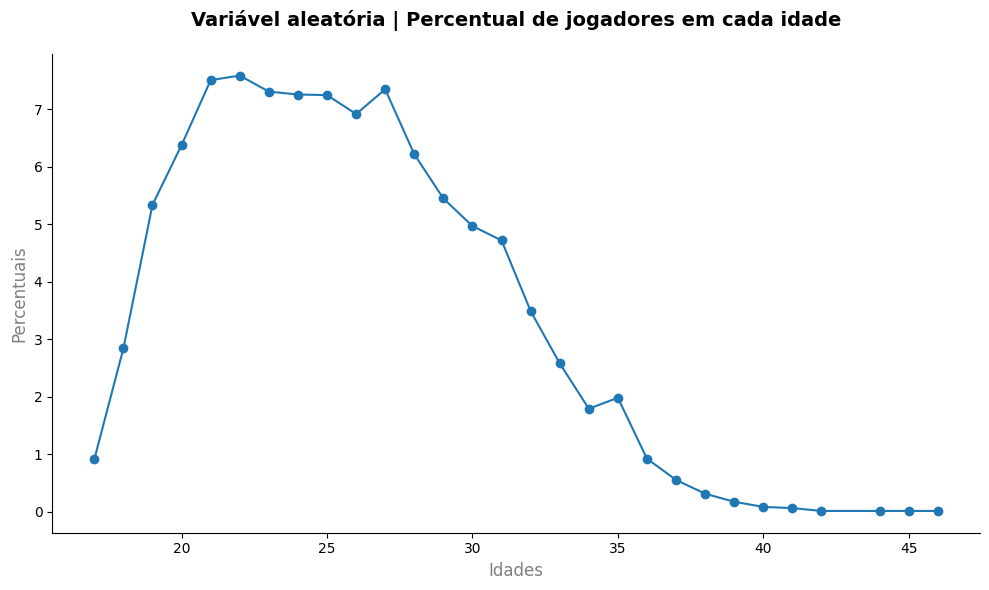

In [ ]:
import matplotlib.pyplot as plt

fig,ax = plt.subplots(figsize=(10,6))

ax.plot(Funcao_Prob, marker='o')

ax.set_title('Variável aleatória | Percentual de jogadores em cada idade', color='black',fontsize=14,fontweight=550,pad=20)
ax.set_xlabel('Idades',color='Gray',fontsize=12)
ax.set_ylabel('Percentuais',color='Gray',fontsize=12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

fig.tight_layout()

### **Função repartição**

Acumulando os dados

In [ ]:
gacumulado =Funcao_Prob.cumsum()
gacumulado

,count
age,
17,0.91
18,3.75
19,9.09
20,15.47
21,22.98
22,30.57
23,37.88
24,45.14
25,52.39


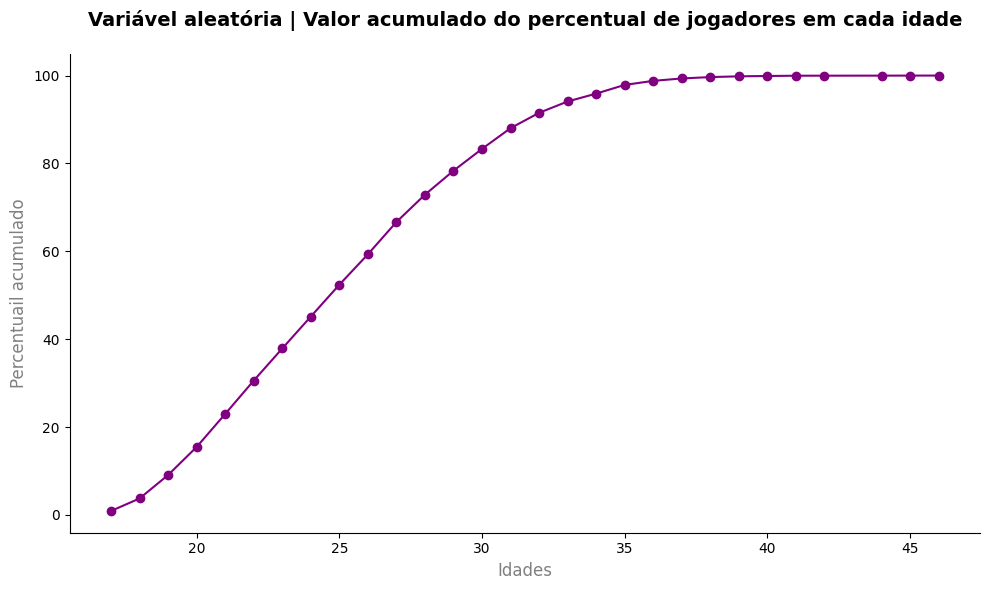

In [ ]:
fig,ax = plt.subplots(figsize=(10,6))

ax.plot(gacumulado, marker='o',color='purple')

ax.set_title('Variável aleatória | Valor acumulado do percentual de jogadores em cada idade', color='black',fontsize=14,fontweight=550,pad=20)
ax.set_xlabel('Idades',color='Gray',fontsize=12)
ax.set_ylabel('Percentuail acumulado',color='Gray',fontsize=12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

fig.tight_layout()

### **Variável aleatória contínua**

Qual a probabilidade de selecionar o peso dos jogadores entre 50-87

In [ ]:
from scipy.stats import norm

peso_jogadores = df["weight_kgs"]
print(peso_jogadores)
print(peso_jogadores.max())
print(peso_jogadores.min())

0        72.1
1        76.2
2        83.9
3        59.0
4        88.9
         ... 
17949    74.8
17950    79.8
17951    89.8
17952    64.9
17953    79.8
Name: weight_kgs, Length: 17898, dtype: float64
110.2
49.9


In [ ]:
lower_bound=50
upper_bound=87

mean=peso_jogadores.mean()
std=peso_jogadores.std()
print(f'{mean} {std}')

x = norm.cdf(upper_bound, loc=mean, scale=std)
y = norm.cdf(lower_bound, loc=mean, scale=std)

probabilidade = x-y

print(f'A probabilidade de estar entre {lower_bound} e {upper_bound} é de {round(probabilidade*100,2)}%')

75.30031847133758 7.081740077933917
A probabilidade de estar entre 50 e 87 é de 95.06%


### **Covariância**

as variáveis dos jogadores posicionamento e a estamina se movem juntas no dataset ? Ou seja se existe um padrão de comportamento entre as duas

In [ ]:
df[['stamina','positioning']].cov()

,stamina,positioning
stamina,253.080070,205.712537
positioning,205.712537,387.716953


Nota-se que existe uma covariância **positiva**, se a estamina do jogador for maior, o posicionamento também **cresce na mesma direção**


### **Correlação**

Agora, alem de ver a direção, busca-se entender a **força** dessa relação (estamina e posicionamento). Ou seja, o quanto esses dados estão **agrupados em torno de uma linha**

In [ ]:
df[['stamina','positioning']].corr()

,stamina,positioning
stamina,1.000000,0.656711
positioning,0.656711,1.000000


Verifica-se uma relação de força **moderada a forte** (0.65) entre a estamina dos jogadores e seu posicionamento. Ou seja, se o jogador tem uma estamina alta, tende a ter um posicionamento alto.


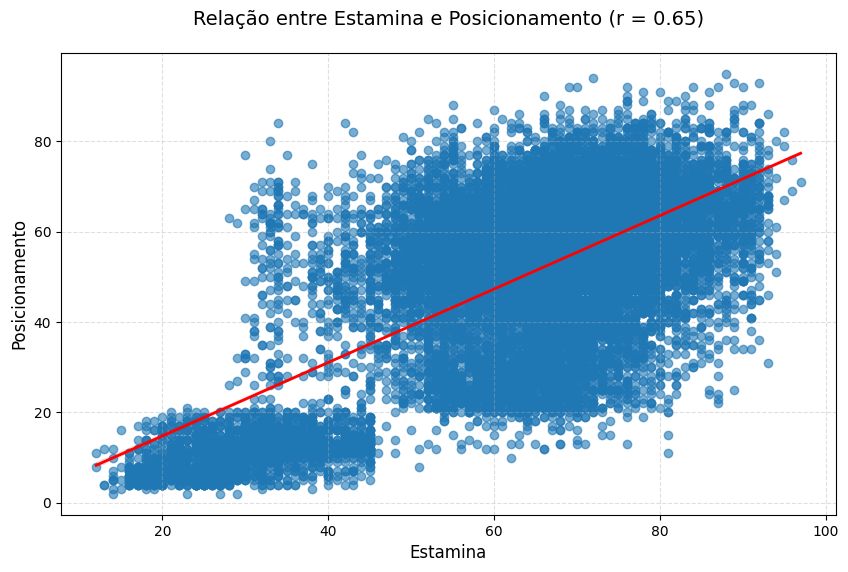

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='stamina',
    y='positioning',
    scatter_kws={'alpha': 0.6, 'color': '#1f77b4'}, # alpha = transparência dos pontos
    line_kws={'color': 'red', 'linewidth': 2}
)


plt.title('Relação entre Estamina e Posicionamento (r = 0.65)', fontsize=14, pad=20)
plt.xlabel('Estamina', fontsize=12)
plt.ylabel('Posicionamento', fontsize=12)


plt.grid(True, linestyle='--', alpha=0.4)


plt.show()

Ao criar o gráfico, nota-se que, no canto inferior esquerdo, existe um quadrado que está praticamente separado da nuvem inicial

Tendo noção de que o dataset se trata de jogadores, temos a *suposição inicial* que essa nuvem separada seja relacionada ao **goleiros**, visto que praticamente nao correm na partida e que a variável posicionamento também não influencia neles

In [ ]:
## criando dataset sem golerios para testar se é verdade o que foi trazido acima
df_sem_goleiro = df[~df['positions'].str.contains('GK')]

In [ ]:
df_sem_goleiro[['stamina','positioning']].corr()

,stamina,positioning
stamina,1.000000,0.272371
positioning,0.272371,1.000000


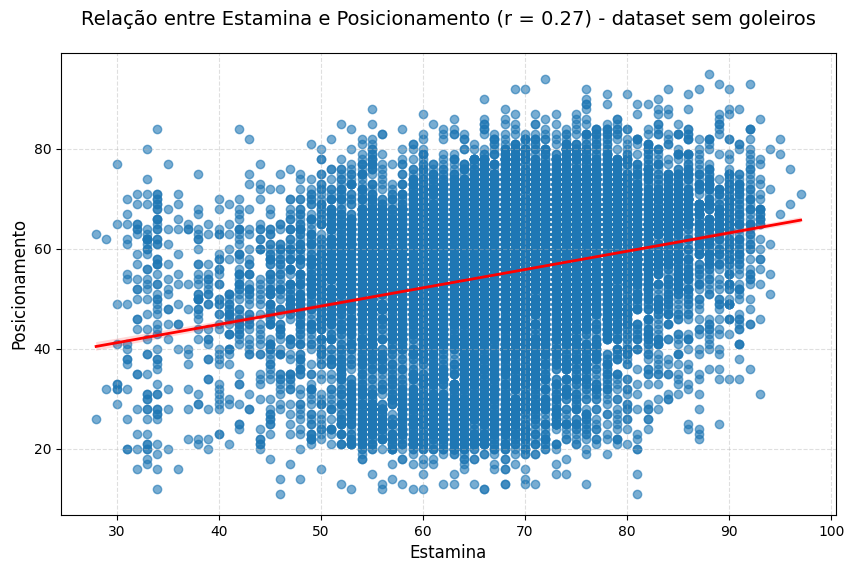

In [ ]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_sem_goleiro,
    x='stamina',
    y='positioning',
    scatter_kws={'alpha': 0.6, 'color': '#1f77b4'}, # alpha = transparência dos pontos
    line_kws={'color': 'red', 'linewidth': 2}
)


plt.title('Relação entre Estamina e Posicionamento (r = 0.27) - dataset sem goleiros', fontsize=14, pad=20)
plt.xlabel('Estamina', fontsize=12)
plt.ylabel('Posicionamento', fontsize=12)


plt.grid(True, linestyle='--', alpha=0.4)



Notamos que, no primeiro momento, quando consideramos todos os dados do dataset, se imaginou que existia uma correlação positiva forte para moderada, mas ao retirar os goleiros, nota-se que **esta correlação se mostrou muito mais fraca**

Isso se dá muito pelos fatos do modelo matemático incial ver os **goleiros com estamina baixa e posicionamento baixo** e criou uma "ilusão de ótica" matemática para nossa análise

## **Estatística Descritiva**


In [ ]:
df.head()

,name,full_name,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,value_euro,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,110500000.0,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,69500000.0,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,25,190.50,83.9,"CM,CAM",France,88,91,73000000.0,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,27,162.56,59.0,"LW,ST",Italy,88,88,62000000.0,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,27,187.96,88.9,CB,Senegal,88,91,60000000.0,...,15,87,88,24,49,33,80,91,88,87


In [ ]:
df['overall_rating'].describe()

,overall_rating
count,17898.000000
mean,66.236730
std,6.965724
min,47.000000
25%,62.000000
50%,66.000000
75%,71.000000
max,94.000000


### **Box plot**

Considerando a avaliação total dos jogadores

Conseguimos percerber que os dados estão bem **concentrados | baixa dispersão**, possuindo poucos pontos chamado de outliers

In [ ]:
import plotly.express as px
fig = px.box(df,
             x='overall_rating',
             hover_name='name',
             hover_data=['positions', 'nationality']
             )
fig.show()

In [ ]:
# Tabela com os outliers nomeados
Q1 = df['overall_rating'].quantile(0.25)
Q3 = df['overall_rating'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[(df['overall_rating'] < limite_inferior) | (df['overall_rating'] > limite_superior)]
print(f"Total de outliers: {len(outliers)} de {len(df)} jogadores ({len(outliers)/len(df)*100:.2f}%)")

outliers.sort_values('overall_rating', ascending=False)[['name', 'overall_rating', 'positions', 'nationality']]

Total de outliers: 162 de 17898 jogadores (0.91%)


,name,overall_rating,positions,nationality
0,L. Messi,94,"CF,RW,ST",Argentina
17944,Cristiano Ronaldo,94,"ST,LW",Portugal
17943,Neymar Jr,92,"LW,CAM",Brazil
17939,L. Modrić,91,CM,Croatia
17938,L. Suárez,91,ST,Uruguay
...,...,...,...,...
4858,A. Kaltner,47,ST,Germany
4861,Zhang Yufeng,47,CM,China PR
4860,C. Ehlich,47,RB,Germany
4859,L. Collins,47,CM,Wales


Separando pelo nível de habilidade (de 1 a 5) dos jogadores

In [ ]:
fig = px.box(df,
             x='skill_moves(1-5)',
             y='overall_rating',
            hover_name='name',
             hover_data=['positions', 'nationality']
             )
fig.show()

### **Histograma**

Nível de estamina dos jogadores visto em forma de histograma

É possível verificar que o valor que possui mais jogadores é 68, contendo 703 jogadores com esse nivel de estamina

In [ ]:
fig = px.histogram(df, x='stamina')
fig.show()

### **Scatter plot**

Fazendo um filtro no banco de dados e retirando os goleiros, podemos verificar pelo scatter plot que existe uma relação **positiva e forte** entre aceleração e sprint.

Jogadores com aceleração alta tendem a ter velorica de sprint alta também e vice-versa

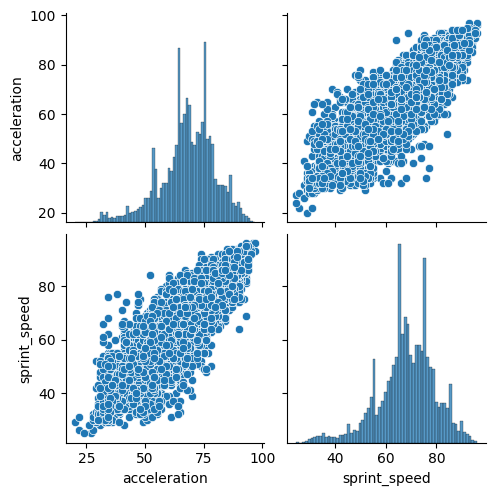

In [ ]:
import seaborn as sns
col=['acceleration', 'sprint_speed']
sns.pairplot(df_sem_goleiro[col])

### **Mapa de calor para correlação**

O mais interessante de observar nesse gráfico é a relação do drible com o chute de longe e a agilidade com o chute de longe.

Jogadores bons em drible tendem a também serem bons em chutes de longa distância. Já agilidade e chute de longe, embora possua uma correlação moderada-forte é significativamente mais baixa (0,85 vs 0,65)

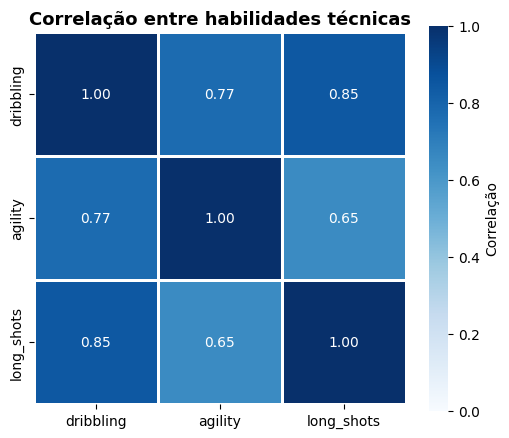

In [ ]:
correlacao = df[['dribbling', 'agility', 'long_shots']].corr()

plt.figure(figsize=(6,5))
sns.heatmap(correlacao, annot=True, cmap='Blues', fmt=".2f",
            vmin=0, vmax=1, square=True, linewidths=1, linecolor='white',
            cbar_kws={'label': 'Correlação'})
plt.title('Correlação entre habilidades técnicas', fontsize=13, fontweight='bold')
plt.show()

## **Distribuição de Probabilidade**



A dsitribuição do **overral_rating** mostram que tanto a distribuição normal quanto a logística decrevem bem os dados

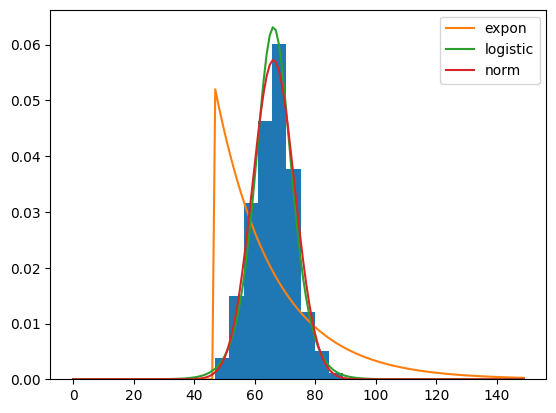

In [ ]:
import scipy.stats
import numpy as np
size=150
x = np.arange(size)
y = df['overall_rating'].values
h = plt.hist(y, density=True)

dist_names = ['expon', 'logistic', 'norm']
for dist_name in dist_names:
  dist = getattr(scipy.stats, dist_name)
  params = dist.fit(y)
  arg = params[:-2]
  loc = params[-2]
  scale = params[-1]
  if arg:
    pdf_fitted = dist.pdf(x, *arg, loc=loc, scale=scale)
  else:
    pdf_fitted = dist.pdf(x, loc=loc, scale=scale)
  plt.plot(pdf_fitted, label=dist_name)

plt.legend(loc= 'upper right')

## **Normalização dos dados**

Utilizando o **StandardScaler e o MinMaxScaler** podemos perceber que fazem a mesma coisa, mudando apenas a escala.

- **StandardScaler** muda a escala entre -2 e 4
- **MinMaxScaler** muda a escala entre 0 e 1



Já que a variável ja tinha uma distribuição assimétricaantes de normalizar, ela **continua** assimetrica depois. A normalização não corrige forma de distribuição, **só ajusta a escala**

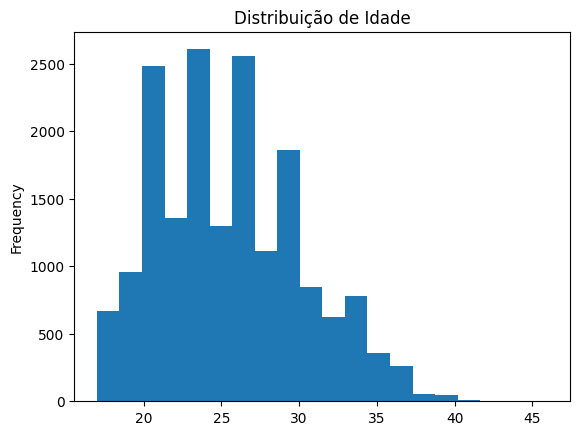

In [ ]:
df['age'].plot(kind='hist', bins=20, title='Distribuição de Idade')
plt.show()

In [ ]:
df.describe()

,age,height_cm,weight_kgs,overall_rating,potential,value_euro,wage_euro,international_reputation(1-5),weak_foot(1-5),skill_moves(1-5),...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
count,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,1.764300e+04,17652.000000,17898.000000,17898.000000,17898.000000,...,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000,17898.000000
mean,25.562968,174.944806,75.300318,66.236730,71.431836,2.478705e+06,9893.723091,1.111465,2.946083,2.361269,...,46.853615,55.817075,46.653313,49.859426,53.399542,48.367359,58.676556,47.161638,47.726729,45.695608
std,4.706764,14.030421,7.081740,6.965724,6.129889,5.690958e+06,21999.297768,0.391751,0.662916,0.763108,...,19.426916,17.384205,20.750502,19.690530,14.152475,15.810614,11.627323,20.029800,21.668324,21.282081
min,17.000000,152.400000,49.900000,47.000000,48.000000,1.000000e+04,1000.000000,1.000000,1.000000,1.000000,...,3.000000,11.000000,3.000000,2.000000,10.000000,5.000000,12.000000,3.000000,2.000000,3.000000
25%,22.000000,154.940000,69.900000,62.000000,67.000000,3.250000e+05,1000.000000,1.000000,3.000000,2.000000,...,32.000000,44.000000,26.000000,38.000000,44.000000,38.000000,51.000000,30.000000,27.000000,24.000000
50%,25.000000,175.260000,74.800000,66.000000,71.000000,7.000000e+05,3000.000000,1.000000,3.000000,2.000000,...,51.000000,59.000000,52.000000,55.000000,55.000000,49.000000,60.000000,52.000000,55.000000,52.000000
75%,29.000000,185.420000,79.800000,71.000000,75.000000,2.100000e+06,9000.000000,1.000000,3.000000,3.000000,...,62.000000,69.000000,64.000000,64.000000,64.000000,60.000000,67.000000,64.000000,66.000000,64.000000
max,46.000000,205.740000,110.200000,94.000000,95.000000,1.105000e+08,565000.000000,5.000000,5.000000,5.000000,...,94.000000,95.000000,92.000000,95.000000,94.000000,92.000000,96.000000,94.000000,93.000000,90.000000


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_normalizado = df
df_normalizado[['age', 'height_cm']]=scaler.fit_transform(df[['age', 'height_cm']])
df_normalizado.head()

,name,full_name,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,value_euro,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,1.155185,-0.339615,72.1,"CF,RW,ST",Argentina,94,94,110500000.0,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,0.305321,-1.425856,76.2,"CAM,RM,CM",Denmark,88,89,69500000.0,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,-0.119612,1.108707,83.9,"CM,CAM",France,88,91,73000000.0,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,0.305321,-0.882736,59.0,"LW,ST",Italy,88,88,62000000.0,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,0.305321,0.927667,88.9,CB,Senegal,88,91,60000000.0,...,15,87,88,24,49,33,80,91,88,87


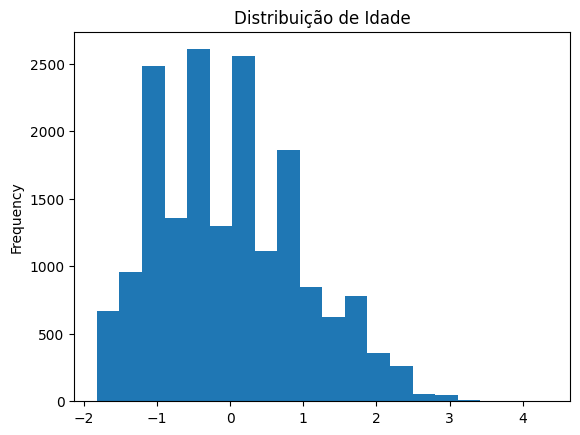

In [ ]:
df_normalizado['age'].plot(kind='hist', bins=20, title='Distribuição de Idade')
plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_minmax = df
df_minmax[['age', 'height_cm']]=scaler.fit_transform(df[['age', 'height_cm']])
df_minmax.head()

,name,full_name,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,value_euro,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,0.482759,0.333333,72.1,"CF,RW,ST",Argentina,94,94,110500000.0,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,0.344828,0.047619,76.2,"CAM,RM,CM",Denmark,88,89,69500000.0,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,0.275862,0.714286,83.9,"CM,CAM",France,88,91,73000000.0,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,0.344828,0.190476,59.0,"LW,ST",Italy,88,88,62000000.0,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,0.344828,0.666667,88.9,CB,Senegal,88,91,60000000.0,...,15,87,88,24,49,33,80,91,88,87


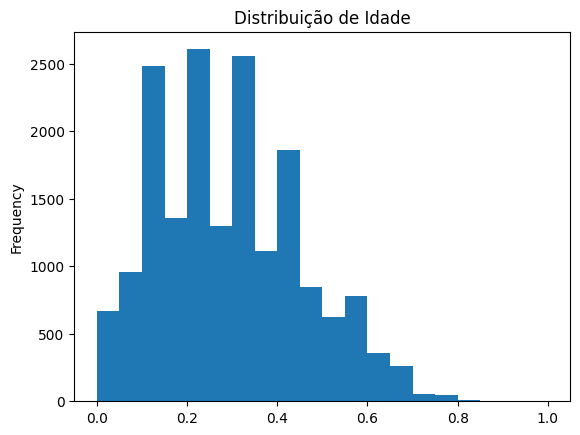

In [ ]:
df_minmax['age'].plot(kind='hist', bins=20, title='Distribuição de Idade')
plt.show()

## **Distribuições amostrais**

Com o teste usado abaixo podemos verificar o **TLC (Teorema do Limite Central)**

Ou seja, não importa qual seja a forma da distribuição original da população, ao calcular a média de cada amostrar, a **distribuição dessas médias vai se aproximar de uma distribuiçaõ normal**

Além da aproximação à normalidade, observa-se a redução do intervalo conforme **n** aumenta

In [ ]:
from numpy.random import choice
from numpy import mean
from matplotlib import pyplot

velocidade = df['sprint_speed']

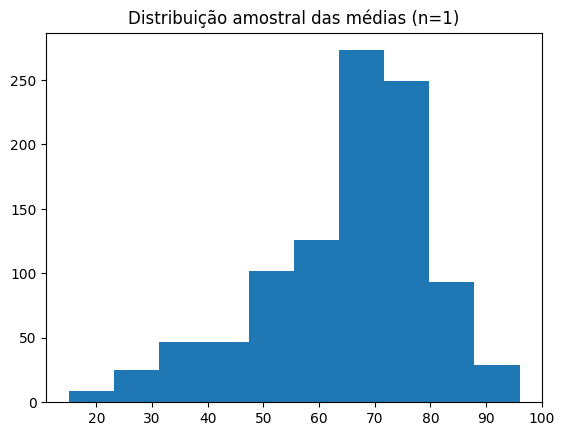

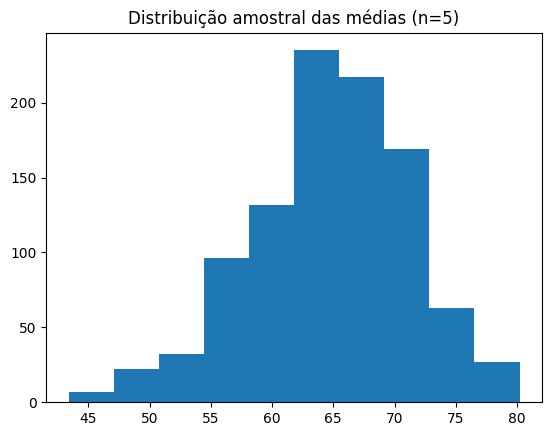

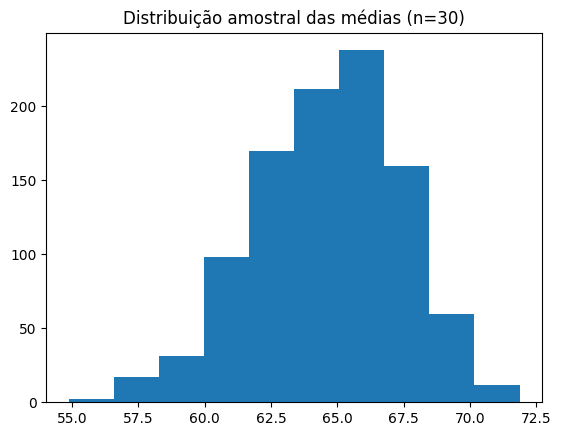

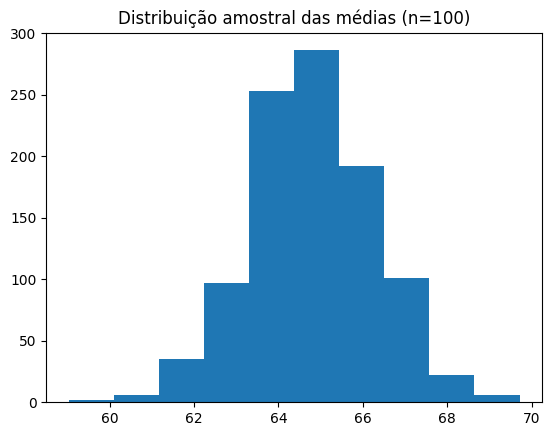

In [ ]:
for n in [1, 5, 30, 100]:
    means = [mean(choice(velocidade, size=n)) for _ in range(1000)]
    pyplot.hist(means)
    pyplot.title(f'Distribuição amostral das médias (n={n})')
    pyplot.show()

## **Intervalo de confiança**

Considerando a variável **overral_rating**, pois garanto que não precisamos retirar os goleiros, podemos ver que a **média da amostra de 100 jogadores é de 66,24**.

O **erro padrão (0,6966)** é usado para estimar o quanto essa média muda ao pegar outras amostras com 100 jogadores, sendo calculado a partir do desvio padrão da amostra dividido pela raiz do tamanho amostral

- Considerando um **nível de confiança de 90%** vemos que a média da população deve estar entre **65,09 e 67,38**

- Considerando um **nível de confiança de 95%** vemos que a média da população deve estar entre **64,87 e 67,60**

Quanto maior o nível de confiança exigido, mais largo precisa ser o intervalo, pois estamos pedindo uma garantia maior de que a média populacional está contida nele.

In [ ]:
import numpy as np
import scipy.stats as stats

# Retirando uma amostra de overall_rating (100 jogadores)
n = 100
amostra = df['overall_rating']

media_amostra = amostra.mean()
desvio_amostra = amostra.std(ddof=1)
erro_padrao = desvio_amostra / np.sqrt(n)

# Intervalo de Confiança de 90% e 95%
ic_90 = stats.norm.interval(0.90, loc=media_amostra, scale=erro_padrao)
ic_95 = stats.norm.interval(0.95, loc=media_amostra, scale=erro_padrao)

print(f"Média da amostra: {media_amostra:.2f}")
print(f"Erro padrão: {erro_padrao:.4f}")
print(f"IC 90%: ({ic_90[0]:.2f}, {ic_90[1]:.2f})")
print(f"IC 95%: ({ic_95[0]:.2f}, {ic_95[1]:.2f})")

Média da amostra: 66.24
Erro padrão: 0.6966
IC 90%: (65.09, 67.38)
IC 95%: (64.87, 67.60)
